# 📈 Predictive Modeling (Regression)
**Task:** Build and evaluate regression models to predict house prices.  
**Requirements:** Train Linear Regression, Decision Trees, Random Forest. Evaluate using MSE and R-squared.  
**Tools:** `pandas`, `scikit-learn`, `matplotlib`

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

# Load Data (Handling whitespace delimiter and no header)
try:
    df = pd.read_csv('data/house_prices.csv', sep='\\s+', header=None)
    print('✅ Data loaded successfully')
except:
    # Fallback to standard csv if formatting changes
    df = pd.read_csv('data/house_prices.csv')

df.head()

✅ Data loaded successfully


,0,1,2,3,4,5,6,7,8,9,10,11,12,13
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2


In [2]:
# Preprocessing (Handling missing values)
df = df.select_dtypes(include='number').fillna(df.median(numeric_only=True))

# Assuming the last column is the target (House Price/MEDV in standard datasets).
target_col = df.columns[-1]
print(f'🎯 Target Column Identified: {target_col}')

X = df.drop(columns=[target_col])
y = df[target_col]

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Split Data
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)
print(f'✅ Data split into Train {X_train.shape} and Test {X_test.shape}')

🎯 Target Column Identified: 13
✅ Data split into Train (404, 13) and Test (102, 13)


In [3]:
# Model Training & Evaluation
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(random_state=42, n_estimators=100)
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    mse = mean_squared_error(y_test, predictions)
    r2 = r2_score(y_test, predictions)
    results.append({'Model': name, 'MSE': mse, 'R2 Score': r2})

results_df = pd.DataFrame(results).sort_values(by='R2 Score', ascending=False)
display(results_df)

,Model,MSE,R2 Score
2,Random Forest,7.927145,0.891903
1,Decision Tree,10.416078,0.857963
0,Linear Regression,24.291119,0.668759


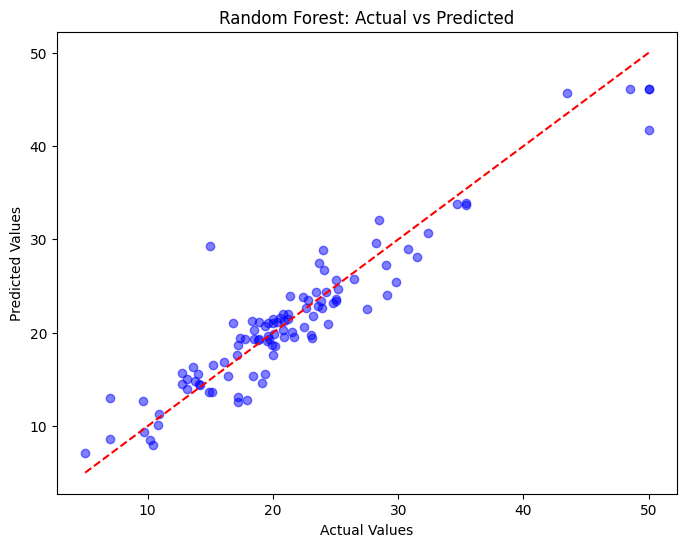

In [4]:
# Visualize Best Model Predictions
best_model_name = results_df.iloc[0]['Model']
best_model = models[best_model_name]
preds = best_model.predict(X_test)

plt.figure(figsize=(8, 6))
plt.scatter(y_test, preds, alpha=0.5, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title(f'{best_model_name}: Actual vs Predicted')
plt.show()

In [5]:

import joblib
import os

os.makedirs('outputs', exist_ok=True)
os.makedirs('models', exist_ok=True)

# Save best model
joblib.dump(best_model, 'models/best_regression_model.pkl')
joblib.dump(scaler, 'models/scaler.pkl')

# Save results
results_df.to_csv('outputs/regression_results.csv', index=False)
print('✅ Saved models and outputs successfully!')


✅ Saved models and outputs successfully!
